In [1]:
"""
Phase B

Dataset Construction

Objetivo:
crear ejemplos supervisados para la adaptación del decoder.

Cada ejemplo contendrá:

- image
- sam mask
- parcel GT
- IoU real
"""

# URL de repositorio
!git clone https://github.com/ZagonTM/Sen4Sam

# Una vez clonado, nos movemos al directorio del repositorio o lo añadimos al path
import os
if os.path.exists('Sen4Sam'):
    %cd Sen4Sam
    print("Acceso al repositorio Sen4Sam exitoso.")
else:
    print("No se pudo encontrar la carpeta del repositorio. Verifica la URL de clonación.")

# Instalar Segment Anything 2 (SAM 2) y sus dependencias
!pip install -q git+https://github.com/facebookresearch/sam2.git

# Instalamos librerias

import sys
from pathlib import Path

import numpy as np
import pandas as pd

from PIL import Image

ROOT = Path.cwd()

sys.path.insert(0, str(ROOT / "src"))

from sam2_auto_segment import (
    build_model,
    build_mask_generator
)


Cloning into 'Sen4Sam'...
remote: Enumerating objects: 132, done.
remote: Counting objects: 100% (132/132), done.
remote: Compressing objects: 100% (89/89), done.
remote: Total 132 (delta 56), reused 107 (delta 40), pack-reused 0 (from 0)
Receiving objects: 100% (132/132), 1.56 MiB | 20.45 MiB/s, done.
Resolving deltas: 100% (56/56), done.
/content/Sen4Sam
Acceso al repositorio Sen4Sam exitoso.
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# Lectura de archivos localizados en google drive

Primero montamos google drive y ubicamos la ruta donde estaran los archivos de interes

In [7]:
from google.colab import drive

drive.mount('/content/drive')

import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):

    if "manifest.csv" in files:

        print(root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Sen4SAM


Definimos nuestra ruta hallada y verificamos archivos

In [17]:
from pathlib import Path

DATA_ROOT = Path(
    "/content/drive/MyDrive/Sen4SAM"
)

print(
    (DATA_ROOT / "manifest.csv").exists()
)

print(
    (DATA_ROOT / "processed.zip").exists()
)

True
True


Descomprimimos archivo zip con imagenes procesadas

In [18]:
import zipfile

zip_path = DATA_ROOT / "processed.zip"

extract_path = DATA_ROOT / "processed"

with zipfile.ZipFile(zip_path,"r") as z:

    z.extractall(extract_path)

print("done")

done


Comprobamos su contenido

In [20]:
import os

processed = DATA_ROOT / "processed" / "processed"

files = os.listdir(processed)

print(len(files))

print(files[:10])

2664
['2019_31TCL_patch_27_08_rgb.png', '2019_31UCP_patch_21_25_parcels.npy', '2019_31TDK_patch_14_25_parcels.npy', '2019_31TBF_patch_18_26_rgb.png', '2019_31TCL_patch_19_23_labels.npy', '2019_31TDK_patch_10_23_labels.npy', '2019_31TCL_patch_22_25_labels.npy', '2019_31TDK_patch_16_14_parcels.npy', '2019_31TDK_patch_29_27_parcels.npy', '2019_31TDK_patch_19_01_parcels.npy']


Ahora cargamos el archivo csv con la informacion requerida. Se verifica el nombre con el que se clasifica cada parametro al revisar la cabecera.

In [23]:
import pandas as pd

manifest = pd.read_csv(
    DATA_ROOT / "manifest.csv"
)

manifest.head()


,country,tile,patch,file,n_acquisitions,n_window_dates,n_clean_dates,chosen_date,mean_cloud,n_fields,field_coverage,eligible,kept
0,ES,31TBF,2019_31TBF_patch_28_08,data/raw/s4a/2019/31TBF/2019_31TBF_patch_28_08.nc,27,2,2,2019-05-01,0.0000,318,0.146,1,1
1,ES,31TBF,2019_31TBF_patch_22_10,data/raw/s4a/2019/31TBF/2019_31TBF_patch_22_10.nc,27,2,2,2019-05-01,0.0000,423,0.114,1,1
2,ES,31TBF,2019_31TBF_patch_26_19,data/raw/s4a/2019/31TBF/2019_31TBF_patch_26_19.nc,27,2,2,2019-05-06,0.0120,19,0.013,1,1
3,ES,31TBF,2019_31TBF_patch_23_16,data/raw/s4a/2019/31TBF/2019_31TBF_patch_23_16.nc,27,2,2,2019-05-06,0.0000,163,0.038,1,1
4,ES,31TBF,2019_31TBF_patch_23_21,data/raw/s4a/2019/31TBF/2019_31TBF_patch_23_21.nc,27,2,2,2019-05-06,0.0004,462,0.330,1,1


In [24]:
print(
    manifest.columns.tolist()
)

['country', 'tile', 'patch', 'file', 'n_acquisitions', 'n_window_dates', 'n_clean_dates', 'chosen_date', 'mean_cloud', 'n_fields', 'field_coverage', 'eligible', 'kept']


# Probamos trabajando con una muestra pequeña

Filtrar únicamente los parches válidos

In [25]:
manifest = manifest[
    manifest["kept"] == 1
]

print("Parches seleccionados:", len(manifest))

Parches seleccionados: 888


No procesaremos las 888 imágenes todavía porque SAM2 puede tardar varios segundos por imagen.

Primero queremos comprobar que todo funciona.

In [26]:
manifest_small = manifest.sample(
    n=10,
    random_state=42
)

manifest_small[
    ["country","tile","patch"]
]

,country,tile,patch
282,ES,31TDG,2019_31TDG_patch_18_17
438,ES,31TCG,2019_31TCG_patch_12_03
39,ES,31TBF,2019_31TBF_patch_24_24
421,ES,31TCG,2019_31TCG_patch_29_16
592,FR,31TCL,2019_31TCL_patch_26_05
813,FR,31UCP,2019_31UCP_patch_14_13
346,ES,31TCG,2019_31TCG_patch_18_12
844,FR,31UCP,2019_31UCP_patch_26_29
587,FR,31TCL,2019_31TCL_patch_23_01
543,FR,31TCL,2019_31TCL_patch_15_22


Escogemos el primer patch del manifest y verificamos

In [27]:
patch = manifest_small.iloc[0]["patch"]

print(patch)

print(
    (DATA_ROOT / "processed"/ "processed" / f"{patch}_rgb.png").exists()
)

print(
    (DATA_ROOT / "processed"/ "processed" / f"{patch}_parcels.npy").exists()
)

2019_31TDG_patch_18_17
True
True


Generamos funciones de lectura

In [28]:
def load_rgb(patch):

    return np.array(
        Image.open(
            DATA_ROOT / "processed"/ "processed" / f"{patch}_rgb.png"
        ).convert("RGB")
    )

In [29]:
def load_parcels(patch):

    return np.load(
        DATA_ROOT / "processed"/ "processed" / f"{patch}_parcels.npy"
    )

Probar con un patch

In [30]:
patch = manifest_small.iloc[0]["patch"]

img = load_rgb(patch)

parcels = load_parcels(patch)

print(img.shape)

print(parcels.shape)

(366, 366, 3)
(366, 366)


Visualizamos imagen y mapa de parcelas

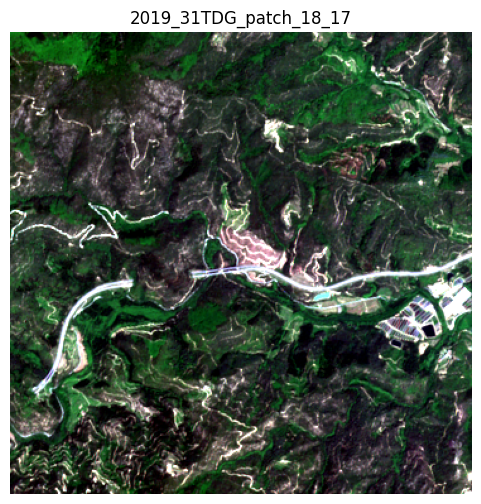

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.imshow(img)

plt.title(patch)

plt.axis("off")

plt.show()

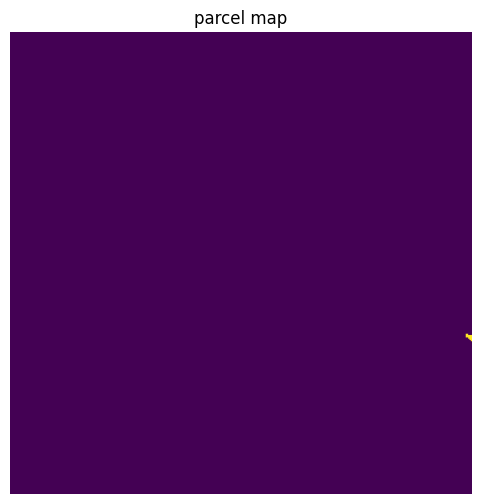

In [32]:
plt.figure(figsize=(6,6))

plt.imshow(parcels)

plt.title("parcel map")

plt.axis("off")

plt.show()

La imagen RGB se ve correctamente y el tamaño coincide con lo esperado (366×366×3).Sin embargo, la visualización de parcelas nos acaba de revelar algo muy interesante , que el mapa parcelario esta casi vacio.
Como se comento en el Notebook 00 , La tesela 31TDG fue seleccionada aleatoriamente y contiene muy poca superficie agrícola.
El mapa parcelario confirma eso visualmente:

* Casi toda la imagen es fondo (parcel_id = 0)

* Únicamente aparece una pequeña región parcelaria en un borde.

Por lo tanto, El archivo se está cargando correctamente pero no es un buen parche para construir inicialmente el dataset de entrenamiento.

# Encontrando un parche adecuado

Queremos encontrar un parche con: field_coverage > 0.5 o incluso > 0.7 .

¿Por qué hacemos esto?

Si usamos ahora un parche casi vacío:

* Obtendremos pocas máscaras útiles.
* Las IoU estarán sesgadas.
* La primera prueba del pipeline será confusa.

In [35]:
manifest.sort_values(
    "field_coverage",
    ascending=False
)[
    ["patch","tile","field_coverage"]
].head(20)


,patch,tile,field_coverage
888,2019_31UCP_patch_25_23,31UCP,0.965
698,2019_31TDK_patch_28_16,31TDK,0.958
840,2019_31UCP_patch_25_21,31UCP,0.951
808,2019_31UCP_patch_27_20,31UCP,0.946
767,2019_31UCP_patch_27_19,31UCP,0.941
774,2019_31UCP_patch_24_17,31UCP,0.934
817,2019_31UCP_patch_21_25,31UCP,0.926
893,2019_31UCP_patch_27_16,31UCP,0.926
851,2019_31UCP_patch_19_10,31UCP,0.925
378,2019_31TCG_patch_08_25,31TCG,0.921


Seleccionamos el de mejor valor

In [36]:
patch = manifest.sort_values(
    "field_coverage",
    ascending=False
).iloc[0]["patch"]

print(patch)

2019_31UCP_patch_25_23


Cargamos el parche y visualizamos

In [37]:
img = load_rgb(patch)

parcels = load_parcels(patch)

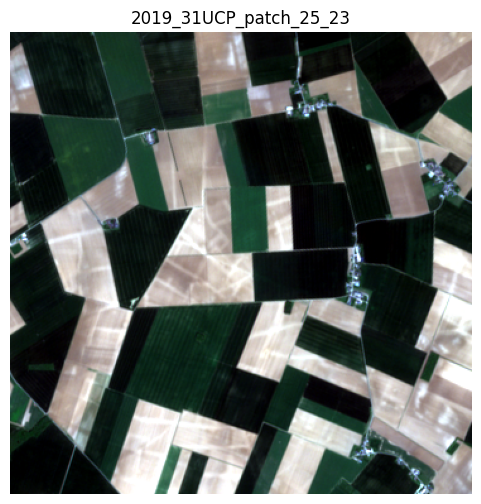

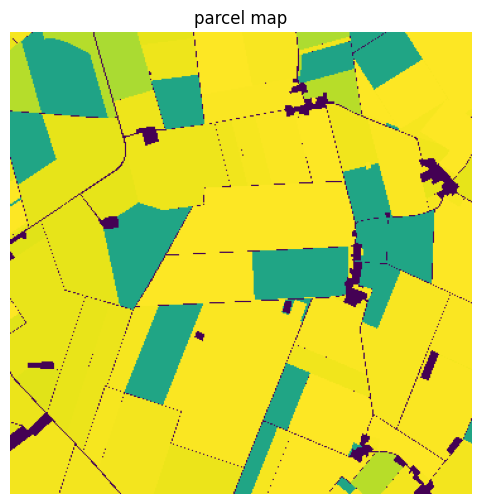

In [38]:
plt.figure(figsize=(6,6))
plt.imshow(img)
plt.title(patch)
plt.axis("off")
plt.show()

plt.figure(figsize=(6,6))
plt.imshow(parcels)
plt.title("parcel map")
plt.axis("off")
plt.show()


La imagen RGB muestra parcelas agrícolas claramente delimitadas y el mapa parcelario asociado contiene muchas instancias agrícolas distribuidas por toda la imagen.

Esto significa que el 96.5% del parche corresponde a suelo agrícola, por lo que es ideal para:

* Generar máscaras SAM2.
* Calcular IoUs.
* Construir el dataset de entrenamiento.
* Analizar errores del decoder.

# Generar las primeras máscaras SAM2

In [3]:
# Crear directorio de checkpoints y descargar los pesos del modelo
!mkdir -p checkpoints
!wget -P checkpoints/ https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
model = build_model()

generator = build_mask_generator(
    model,
    points_per_side=16,
    pred_iou_thresh=0.5,
    stability_score_thresh=0.8
)

--2026-11-07 22:29:14--  https://dl.fbaipublicfiles.com/segment_anything_2/092824/sam2.1_hiera_small.pt
Resolving dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)... 65.9.168.4, 65.9.168.81, 65.9.168.62, ...
Connecting to dl.fbaipublicfiles.com (dl.fbaipublicfiles.com)|65.9.168.4|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 184416285 (176M) [application/vnd.snesdev-page-table]
Saving to: ‘checkpoints/sam2.1_hiera_small.pt’

sam2.1_hiera_small. 100%[===================>] 175.87M   314MB/s    in 0.6s    

2026-11-07 22:29:14 (314 MB/s) - ‘checkpoints/sam2.1_hiera_small.pt’ saved [184416285/184416285]



/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


Generamos las mascaras

In [39]:
masks = generator.generate(img)

print("Número de máscaras:", len(masks))

Número de máscaras: 110


Inspeccionamos y visualizamos una mascara

In [40]:
print(masks[0].keys())

dict_keys(['segmentation', 'area', 'bbox', 'predicted_iou', 'point_coords', 'stability_score', 'crop_box'])


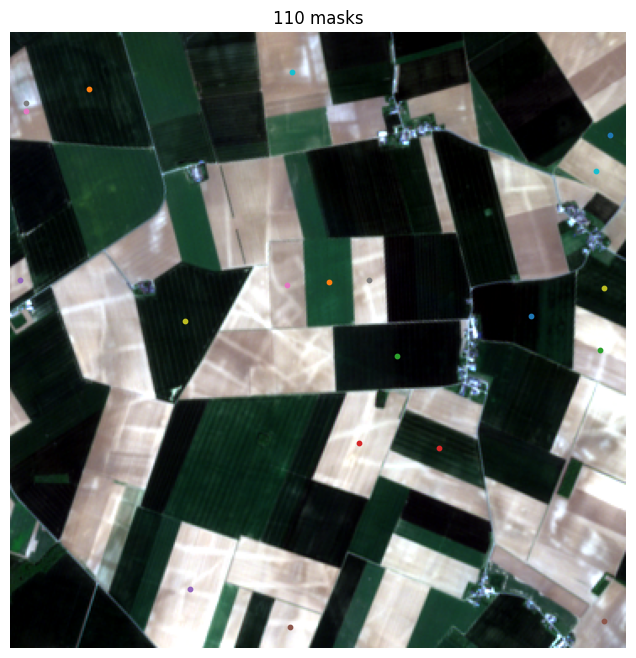

In [41]:
import matplotlib.pyplot as plt
import numpy as np

plt.figure(figsize=(8,8))

plt.imshow(img)

for m in masks[:20]:

    seg = m["segmentation"]

    y, x = np.where(seg)

    if len(x) > 0:

        plt.scatter(
            x.mean(),
            y.mean(),
            s=10
        )

plt.title(
    f"{len(masks)} masks"
)

plt.axis("off")

plt.show()

Al aparecer predicted_iou, ya podremos comprobar experimentalmente la hipótesis principal de la Fase B:

¿Está realmente mal calibrado el IoU Prediction Head sobre imágenes Sentinel-2?

# Comprobando calibracion de IoU Prediction Head

Función IoU

In [42]:
def iou(mask_a, mask_b):

    inter = np.logical_and(
        mask_a,
        mask_b
    ).sum()

    union = np.logical_or(
        mask_a,
        mask_b
    ).sum()

    return inter / max(union,1)

Mejor parcela para una máscara

In [43]:
def best_gt_iou(mask, parcels):

    best = 0.0

    for pid in np.unique(parcels):

        if pid == 0:
            continue

        gt = parcels == pid

        best = max(
            best,
            iou(mask,gt)
        )

    return best

Analizar las primeras 30 máscaras

In [44]:
rows = []

for m in masks[:30]:

    pred_iou = m["predicted_iou"]

    mask = m["segmentation"]

    true_iou = best_gt_iou(
        mask,
        parcels
    )

    rows.append({

        "pred_iou":pred_iou,

        "true_iou":true_iou,

        "area":m["area"]

    })

DataFrame

In [45]:
import pandas as pd

df = pd.DataFrame(rows)

df.head()

,pred_iou,true_iou,area
0,0.973092,0.859712,527
1,0.971395,0.490114,3844
2,0.971328,0.927867,2789
3,0.969840,0.501642,2105
4,0.968559,0.853383,256


Resumen estadístico

In [46]:
df.describe()

,pred_iou,true_iou,area
count,30.000000,30.000000,30.000000
mean,0.960208,0.798250,1748.766667
std,0.006792,0.192365,1344.092482
min,0.949514,0.355222,256.000000
25%,0.956115,0.721443,905.750000
50%,0.959178,0.897895,1310.000000
75%,0.965795,0.933086,2363.250000
max,0.973092,0.948737,6999.000000


Visualizamos predicho IoU vs real IoU

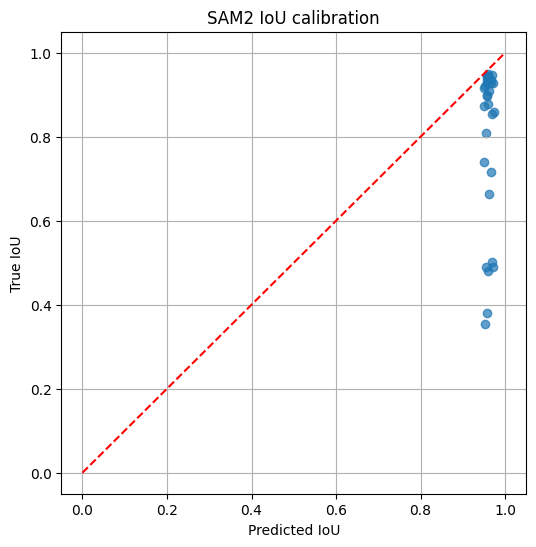

In [47]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(
    df["pred_iou"],
    df["true_iou"],
    alpha=0.7
)

plt.plot(
    [0,1],
    [0,1],
    color="red",
    linestyle="--"
)

plt.xlabel("Predicted IoU")

plt.ylabel("True IoU")

plt.title(
    "SAM2 IoU calibration"
)

plt.grid(True)

plt.show()

La grafica de calibracio es muy reveladora. Si el IoU head estuviera bien calibrado entonces los puntos deberían caer
sobre la diagonal roja.
Pero observamos:

* Casi todos los valores predichos están comprimidos alrededor de 0.95
* Los IoU reales tienen bastante más variabilidad
* Existen máscaras con:

  * pred_iou ≈ 0.95

  * true_iou ≈ 0.35
Eso significa que el decoder prácticamente considera muchas máscaras como "excelentes" aunque algunas son claramente peores.

Entonces la hipotesis se confirma. El IoU Prediction Head parece mal calibrado para Sentinel‑2, ya que las puntuaciones predichas presentan poca variabilidad y tienden a sobreestimar la calidad real de algunas máscaras.

In [48]:
corr = df["pred_iou"].corr(
    df["true_iou"]
)

print(
    f"Correlation = {corr:.4f}"
)

Correlation = -0.0087


El IoU Prediction Head prácticamente no está correlacionado con la calidad real de las máscaras en este subconjunto de imágenes Sentinel‑2.

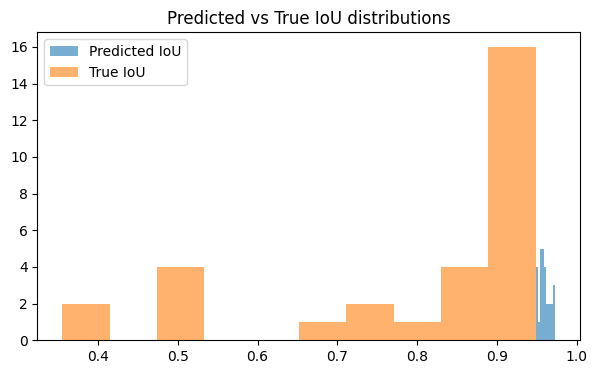

In [49]:
plt.figure(figsize=(7,4))

plt.hist(
    df["pred_iou"],
    bins=10,
    alpha=0.6,
    label="Predicted IoU"
)

plt.hist(
    df["true_iou"],
    bins=10,
    alpha=0.6,
    label="True IoU"
)

plt.legend()

plt.title(
    "Predicted vs True IoU distributions"
)

plt.show()

En la grafica de distrubuciones observamos:
* Predicted IoU:
muy concentrado alrededor de 0.95

* True IoU:
mucho más disperso